# Kernel methods — E. coli, Hospital A

**Role (team plan):** PCA, kernel PCA (RBF), spectral-region check.

**Data:** `shared_data/spectra_ecoli_A.npy` (7,320 spectra × 6,000 bins) and `shared_data/labels_ecoli_A.csv` (R=1, S=0, empty = not tested; fixed folds 0–4, −1 = no label). Put the `shared_data` folder next to this notebook.

**Rules followed:** `run_cv`, the folds and `MODEL_ABX` are copied unchanged from the starter notebook. Every reducer is fitted on the training folds only. Each method is saved as `results_<method>.csv` with the columns `antibiotic, method, auc, auc_std, prauc, n_features`.

**Methods in this notebook**

| Step | Method name | What it is |
|---|---|---|
| 2 | `pca_50`, `pca_200` | PCA with 50 / 200 components |
| 3 | `kpca_rbf_200`, `kpca_linear_200` | Kernel PCA (RBF, linear), 200 components, re-scaled |
| 4a | — | Spectral-region map (PCA-200 weights mapped back to bins) |
| 4b | `pca_region_top100` | Keep only the 100 strongest bins from the region map |

All settings were fixed before running the 12 antibiotics, except k = 100 in Step 4b, which was fixed from a pilot on three antibiotics (Ceftriaxone, Cefepime, Tobramycin; k = 100, 300, 600).

## Setup: shared data and the common test (copied unchanged from the starter notebook)

In [ ]:
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score

# Spectra: one row per E. coli isolate, 6,000 bins (columns)
X = np.load("shared_data/spectra_ecoli_A.npy")

# Labels: R=1, S=0, empty = not tested. fold_<antibiotic> = fold number 0-4 (-1 = no label)
lab = pd.read_csv("shared_data/labels_ecoli_A.csv")

# The 12 antibiotics we model (the other 3 have too few R or S)
MODEL_ABX = ["Ampicillin-Amoxicillin", "Cotrimoxazole", "Ciprofloxacin", "Levofloxacin",
             "Amoxicillin-Clavulanic acid", "Ceftriaxone", "Cefpodoxime", "Tobramycin",
             "Ceftazidime", "Norfloxacin", "Cefepime", "Piperacillin-Tazobactam"]

print(X.shape, lab.shape)   # expected (7320, 6000) (7320, 32)

(7320, 6000) (7320, 32)


In [ ]:
def run_cv(reducer, antibiotic):
    """reducer = object with fit(X, y) / transform(X), or None for no reduction."""
    has_label = (lab[antibiotic].notna()) & (lab[f"fold_{antibiotic}"] >= 0)
    Xa = X[has_label.values]                                   # spectra with an R/S result
    ya = lab.loc[has_label, antibiotic].astype(int).values     # R=1, S=0
    fa = lab.loc[has_label, f"fold_{antibiotic}"].values       # fold number 0-4

    aucs, praucs, n_feats = [], [], []
    for k in range(5):
        tr, te = fa != k, fa == k                  # train = other 4 folds, test = fold k
        steps = [StandardScaler()]                 # put all bins on the same scale
        if reducer is not None:
            steps.append(clone(reducer))           # fresh copy, fitted on train only
        steps.append(LogisticRegression(max_iter=1000))   # simple classifier
        model = make_pipeline(*steps).fit(Xa[tr], ya[tr])

        p = model.predict_proba(Xa[te])[:, 1]      # probability of resistant
        aucs.append(roc_auc_score(ya[te], p))
        praucs.append(average_precision_score(ya[te], p))
        n_feats.append(model[:-1].transform(Xa[te][:5]).shape[1])   # features the classifier saw

    return {"antibiotic": antibiotic, "auc": np.mean(aucs), "auc_std": np.std(aucs),
            "prauc": np.mean(praucs), "n_features": int(np.mean(n_feats))}

In [ ]:
import warnings
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings("default", category=ConvergenceWarning)
from sklearn.decomposition import PCA, KernelPCA
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

def run_all(METHOD_NAME, my_reducer):
    """Run one method on the 12 antibiotics with run_cv and save results_<METHOD_NAME>.csv."""
    rows = []
    for abx in MODEL_ABX:
        r = run_cv(my_reducer, abx)
        r["method"] = METHOD_NAME
        rows.append(r)
        print(METHOD_NAME, abx, "AUC =", round(r["auc"], 3),
              "| PR-AUC =", round(r["prauc"], 3), "| features =", r["n_features"])
    res = pd.DataFrame(rows)[["antibiotic", "method", "auc", "auc_std", "prauc", "n_features"]]
    res.to_csv(f"results_{METHOD_NAME}.csv", index=False)
    print(METHOD_NAME, "mean AUC =", round(res.auc.mean(), 3),
          "| mean PR-AUC =", round(res.prauc.mean(), 3), "\n")
    return res

## Step 0: Data check
Expected: no missing values; Cefepime R = 335, S = 4,051.

In [ ]:
import sklearn
print("sklearn", sklearn.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)
print("Any missing values in spectra?", np.isnan(X).any())
print("Cefepime: R =", int((lab["Cefepime"] == 1).sum()), "| S =", int((lab["Cefepime"] == 0).sum()))

sklearn 1.8.0 | numpy 2.4.2 | pandas 2.3.3
Any missing values in spectra? False
Cefepime: R = 335 | S = 4051


## Step 1: Baseline check (all 6,000 bins, no reduction)

In [ ]:
rows = []
for abx in MODEL_ABX:
    r = run_cv(None, abx)
    rows.append(r)
    print(abx, "AUC =", round(r["auc"], 3), "| PR-AUC =", round(r["prauc"], 3))
base = pd.DataFrame(rows)
base.to_csv("baseline_check.csv", index=False)
print("\nMean AUC =", round(base.auc.mean(), 3), "| Mean PR-AUC =", round(base.prauc.mean(), 3))

Ampicillin-Amoxicillin AUC = 0.647 | PR-AUC = 0.725
Cotrimoxazole AUC = 0.641 | PR-AUC = 0.454
Ciprofloxacin AUC = 0.786 | PR-AUC = 0.631
Levofloxacin AUC = 0.783 | PR-AUC = 0.627
Amoxicillin-Clavulanic acid AUC = 0.616 | PR-AUC = 0.339
Ceftriaxone AUC = 0.842 | PR-AUC = 0.676
Cefpodoxime AUC = 0.835 | PR-AUC = 0.827
Tobramycin AUC = 0.698 | PR-AUC = 0.249
Ceftazidime AUC = 0.796 | PR-AUC = 0.426
Norfloxacin AUC = 0.759 | PR-AUC = 0.583
Cefepime AUC = 0.84 | PR-AUC = 0.403
Piperacillin-Tazobactam AUC = 0.687 | PR-AUC = 0.178

Mean AUC = 0.744 | Mean PR-AUC = 0.51


## Step 2: PCA
PCA finds the directions of largest variation between the training spectra. Each component is a weighted mix of all 6,000 bins. PCA is unsupervised (labels are not used). `random_state=0` makes the randomized solver repeatable.

In [ ]:
res_pca50  = run_all("pca_50",  PCA(n_components=50,  random_state=0))
res_pca200 = run_all("pca_200", PCA(n_components=200, random_state=0))

pca_50 Ampicillin-Amoxicillin AUC = 0.654 | PR-AUC = 0.751 | features = 50
pca_50 Cotrimoxazole AUC = 0.66 | PR-AUC = 0.467 | features = 50
pca_50 Ciprofloxacin AUC = 0.793 | PR-AUC = 0.675 | features = 50
pca_50 Levofloxacin AUC = 0.799 | PR-AUC = 0.685 | features = 50
pca_50 Amoxicillin-Clavulanic acid AUC = 0.637 | PR-AUC = 0.378 | features = 50
pca_50 Ceftriaxone AUC = 0.811 | PR-AUC = 0.62 | features = 50
pca_50 Cefpodoxime AUC = 0.833 | PR-AUC = 0.837 | features = 50
pca_50 Tobramycin AUC = 0.706 | PR-AUC = 0.292 | features = 50
pca_50 Ceftazidime AUC = 0.801 | PR-AUC = 0.424 | features = 50
pca_50 Norfloxacin AUC = 0.769 | PR-AUC = 0.615 | features = 50
pca_50 Cefepime AUC = 0.847 | PR-AUC = 0.398 | features = 50
pca_50 Piperacillin-Tazobactam AUC = 0.688 | PR-AUC = 0.169 | features = 50
pca_50 mean AUC = 0.75 | mean PR-AUC = 0.526 

pca_200 Ampicillin-Amoxicillin AUC = 0.689 | PR-AUC = 0.783 | features = 200
pca_200 Cotrimoxazole AUC = 0.683 | PR-AUC = 0.49 | features = 200
pca

## Step 3: Kernel PCA (RBF and linear)
Kernel PCA builds an N × N similarity matrix between training spectra and runs PCA on it (Eq. 1 in Guerrero-López et al., 2023).
- **Linear kernel** K(a,b) = aᵀb (Eq. 8): equivalent to PCA, used as a sanity check.
- **RBF kernel** K(a,b) = exp(−γ‖a−b‖²) (Eq. 7): captures non-linear similarity. γ = sklearn default 1/n_features = 1/6000 (not tuned).

Kernel PCA components have very small values, which the default L2 penalty of the logistic regression suppresses. The components are therefore re-scaled with a `StandardScaler` inside the reducer (`run_cv` is unchanged).

In [ ]:
class KernelPCAScaled(BaseEstimator, TransformerMixin):
    """Kernel PCA, then re-scale the components (same structure as LassoSelect)."""
    def __init__(self, n_components=200, kernel="rbf", gamma=None):
        self.n_components = n_components   # how many components to keep
        self.kernel = kernel               # "rbf" or "linear"
        self.gamma = gamma                 # None = sklearn default 1/n_features = 1/6000

    def fit(self, X, y=None):              # y is not used: kernel PCA is unsupervised
        self.kpca_ = KernelPCA(n_components=self.n_components, kernel=self.kernel,
                               gamma=self.gamma, eigen_solver="randomized", random_state=0)
        Z = self.kpca_.fit_transform(X)    # N x N kernel matrix from TRAINING spectra only
        self.scaler_ = StandardScaler().fit(Z)
        return self

    def transform(self, X):                # test spectra are compared with the training spectra
        return self.scaler_.transform(self.kpca_.transform(X))

res_rbf = run_all("kpca_rbf_200",    KernelPCAScaled(n_components=200, kernel="rbf"))
res_lin = run_all("kpca_linear_200", KernelPCAScaled(n_components=200, kernel="linear"))

kpca_rbf_200 Ampicillin-Amoxicillin AUC = 0.69 | PR-AUC = 0.789 | features = 200
kpca_rbf_200 Cotrimoxazole AUC = 0.694 | PR-AUC = 0.501 | features = 200
kpca_rbf_200 Ciprofloxacin AUC = 0.808 | PR-AUC = 0.703 | features = 200
kpca_rbf_200 Levofloxacin AUC = 0.813 | PR-AUC = 0.703 | features = 200
kpca_rbf_200 Amoxicillin-Clavulanic acid AUC = 0.662 | PR-AUC = 0.429 | features = 200
kpca_rbf_200 Ceftriaxone AUC = 0.858 | PR-AUC = 0.723 | features = 200
kpca_rbf_200 Cefpodoxime AUC = 0.852 | PR-AUC = 0.853 | features = 200
kpca_rbf_200 Tobramycin AUC = 0.739 | PR-AUC = 0.322 | features = 200
kpca_rbf_200 Ceftazidime AUC = 0.825 | PR-AUC = 0.492 | features = 200
kpca_rbf_200 Norfloxacin AUC = 0.76 | PR-AUC = 0.592 | features = 200
kpca_rbf_200 Cefepime AUC = 0.856 | PR-AUC = 0.442 | features = 200
kpca_rbf_200 Piperacillin-Tazobactam AUC = 0.702 | PR-AUC = 0.173 | features = 200
kpca_rbf_200 mean AUC = 0.772 | mean PR-AUC = 0.56 

kpca_linear_200 Ampicillin-Amoxicillin AUC = 0.69 | PR-AU

## Step 4a: Spectral-region check

The PCA-200 and Logistic Regression coefficients are back-projected to the original 6,000 spectral bins to identify candidate predictive features.

Positive coefficients indicate a positive contribution to the predicted resistance log-odds, while negative coefficients indicate a negative contribution, conditional on the other standardized features. These coefficients do not directly establish whether spectral intensity is higher in resistant or susceptible isolates.

The analysis is repeated across the five training-fold models, and the resulting coefficients are averaged. Stability is assessed using the mean overlap of the top-60 bins across folds.

Because the original m/z calibration has not been verified, all results are reported using spectral bin indices (0–5999), not inferred m/z values.

**Outputs:** `regions_pca200_top5.csv` and `fig_region_heatmap.png`.

The identified regions are exploratory candidate predictive features, not experimentally validated resistance biomarkers.

Ampicillin-Amoxicillin       fold overlap of top-60 bins = 0.69
Cotrimoxazole                fold overlap of top-60 bins = 0.51
Ciprofloxacin                fold overlap of top-60 bins = 0.86
Levofloxacin                 fold overlap of top-60 bins = 0.85
Amoxicillin-Clavulanic acid  fold overlap of top-60 bins = 0.48
Ceftriaxone                  fold overlap of top-60 bins = 0.77
Cefpodoxime                  fold overlap of top-60 bins = 0.57
Tobramycin                   fold overlap of top-60 bins = 0.51
Ceftazidime                  fold overlap of top-60 bins = 0.66
Norfloxacin                  fold overlap of top-60 bins = 0.52
Cefepime                     fold overlap of top-60 bins = 0.51
Piperacillin-Tazobactam      fold overlap of top-60 bins = 0.24


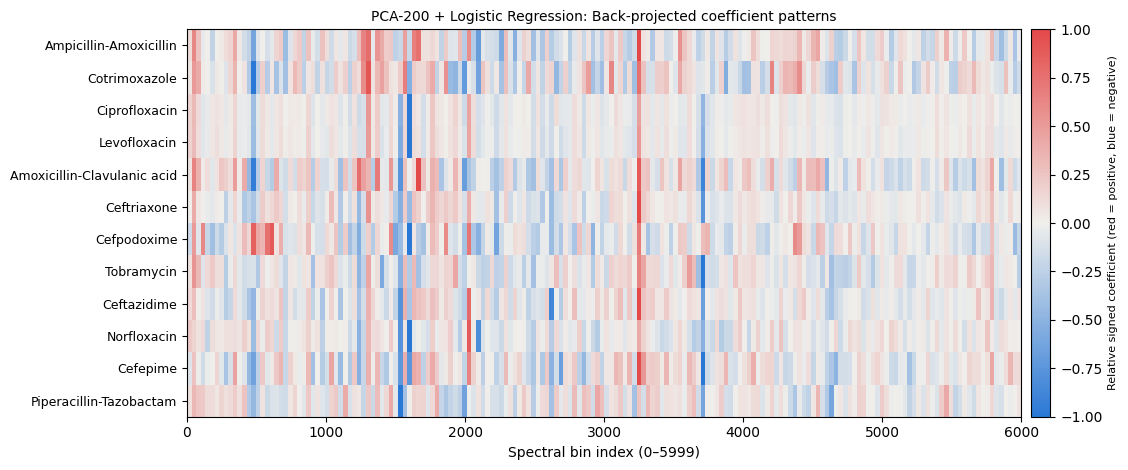

,antibiotic,rank,start_bin,end_bin,direction,strength,fold_overlap_top60
0,Ampicillin-Amoxicillin,1,3257,3262,positive resistance-score coefficient,0.172,0.69
1,Ampicillin-Amoxicillin,2,1295,1298,positive resistance-score coefficient,0.111,0.69
2,Ampicillin-Amoxicillin,3,1632,1635,positive resistance-score coefficient,0.110,0.69
5,Cotrimoxazole,1,3256,3262,positive resistance-score coefficient,0.150,0.51
6,Cotrimoxazole,2,1295,1303,positive resistance-score coefficient,0.146,0.51
7,Cotrimoxazole,3,466,468,negative resistance-score coefficient,0.045,0.51
10,Ciprofloxacin,1,3257,3263,positive resistance-score coefficient,0.404,0.86
11,Ciprofloxacin,2,1600,1605,negative resistance-score coefficient,0.312,0.86
12,Ciprofloxacin,3,1295,1299,positive resistance-score coefficient,0.296,0.86
15,Levofloxacin,1,3257,3263,positive resistance-score coefficient,0.406,0.85


In [ ]:
# Actual m/z calibration has not yet been verified.
# Interpret the current results using spectral bin indices (0–5999).

def bin_weights(abx, n_comp=200):
    """Per fold: scale -> PCA -> LR on TRAINING folds only; map LR weights back to the 6,000 bins."""
    has = (lab[abx].notna()) & (lab[f"fold_{abx}"] >= 0)
    Xa = X[has.values]; ya = lab.loc[has, abx].astype(int).values; fa = lab.loc[has, f"fold_{abx}"].values
    W = []
    for k in range(5):
        tr = fa != k
        Z = StandardScaler().fit_transform(Xa[tr])
        pca = PCA(n_components=n_comp, random_state=0).fit(Z)
        lr = LogisticRegression(max_iter=1000).fit(pca.transform(Z), ya[tr])
        W.append(pca.components_.T @ lr.coef_[0])       
        # Positive coefficient = positive contribution to predicted resistance log-odds
        # in standardized spectral coordinates.    
    return np.array(W)                                       # (5 folds, 6000 bins)

def top_regions(w, n_bins=30):
    """Group nearby high-magnitude coefficients by sign, using bin indices."""
    top = np.sort(np.argsort(-np.abs(w))[:n_bins])
    regions = []
    cur = [top[0]]
    for b in top[1:]:
        if b - cur[-1] <= 2 and np.sign(w[b]) == np.sign(w[cur[-1]]):
            cur.append(b)
        else:
            regions.append(cur)
            cur = [b]
    regions.append(cur)
    out = [
        {
            "start_bin": int(r[0]),
            "end_bin": int(r[-1]),
            "direction": (
                "positive resistance-score coefficient"
                if w[r[0]] > 0
                else "negative resistance-score coefficient"
            ),
            "strength": float(np.abs(w[r]).sum())
        }
        for r in regions
    ]
    return sorted(out, key=lambda d: -d["strength"])

all_W, rows = {}, []
for abx in MODEL_ABX:
    W = bin_weights(abx); w = W.mean(0); all_W[abx] = w
    tops = [set(np.argsort(-np.abs(r))[:60]) for r in W]
    overlap = np.mean([len(tops[i] & tops[j]) / 60 for i in range(5) for j in range(i + 1, 5)])
    for rank, reg in enumerate(top_regions(w)[:5], 1):
        rows.append({"antibiotic": abx, "rank": rank, **reg, "fold_overlap_top60": round(overlap, 2)})
    print(f"{abx:28s} fold overlap of top-60 bins = {overlap:.2f}")

regions = pd.DataFrame(rows); regions["strength"] = regions["strength"].round(3)
regions.to_csv("regions_pca200_top5.csv", index=False)

WINDOW_BINS = 33

M = np.array([
    [
        all_W[a][i:i + WINDOW_BINS].sum()
        for i in range(0, X.shape[1], WINDOW_BINS)
    ]
    for a in MODEL_ABX
])
denom = np.abs(M).max(axis=1, keepdims=True)
M = M / np.maximum(denom, 1e-12)
cmap = LinearSegmentedColormap.from_list(
    "SR", ["#2a78d6", "#f0efec", "#e34948"]
)
fig, ax = plt.subplots(figsize=(12, 4.8))
im = ax.imshow(
    M,
    aspect="auto",
    cmap=cmap,
    vmin=-1,
    vmax=1,
    extent=[0, X.shape[1], len(MODEL_ABX) - 0.5, -0.5]
)
ax.set_yticks(range(len(MODEL_ABX)))
ax.set_yticklabels(MODEL_ABX, fontsize=9)
ax.set_xlabel("Spectral bin index (0–5999)")
ax.set_title(
    "PCA-200 + Logistic Regression: "
    "Back-projected coefficient patterns",
    fontsize=10
)
cb = fig.colorbar(im, ax=ax, pad=0.01)
cb.set_label(
    "Relative signed coefficient "
    "(red = positive, blue = negative)",
    fontsize=8
)
plt.tight_layout()
plt.savefig("fig_region_heatmap.png", dpi=200)
plt.show()
display(regions[regions["rank"] <= 3])

## Step 4b: Keep only the top-100 bins
Inside each training fold: fit PCA-200 + LR, map the weights to bins, keep the 100 strongest bins. The classifier then sees only those 100 real bins (1.7% of the spectrum). k = 100 was fixed from a pilot on three antibiotics.

In [ ]:
class PCARegionSelect(BaseEstimator, TransformerMixin):
    """Fit PCA + LR on the training folds, map weights back to bins, keep the k strongest bins."""
    def __init__(self, k=100, n_components=200):
        self.k = k
        self.n_components = n_components

    def fit(self, X, y):                    # X is already scaled by run_cv
        pca = PCA(n_components=self.n_components, random_state=0).fit(X)
        lr = LogisticRegression(max_iter=1000).fit(pca.transform(X), y)
        self.bin_weight_ = pca.components_.T @ lr.coef_[0]
        self.keep_ = np.sort(np.argsort(-np.abs(self.bin_weight_))[:self.k])
        return self

    def transform(self, X):
        return X[:, self.keep_]

res_top100 = run_all("pca_region_top100", PCARegionSelect(k=100))

pca_region_top100 Ampicillin-Amoxicillin AUC = 0.667 | PR-AUC = 0.767 | features = 100
pca_region_top100 Cotrimoxazole AUC = 0.664 | PR-AUC = 0.479 | features = 100
pca_region_top100 Ciprofloxacin AUC = 0.796 | PR-AUC = 0.681 | features = 100
pca_region_top100 Levofloxacin AUC = 0.804 | PR-AUC = 0.689 | features = 100
pca_region_top100 Amoxicillin-Clavulanic acid AUC = 0.644 | PR-AUC = 0.408 | features = 100
pca_region_top100 Ceftriaxone AUC = 0.848 | PR-AUC = 0.711 | features = 100
pca_region_top100 Cefpodoxime AUC = 0.847 | PR-AUC = 0.849 | features = 100
pca_region_top100 Tobramycin AUC = 0.708 | PR-AUC = 0.295 | features = 100
pca_region_top100 Ceftazidime AUC = 0.802 | PR-AUC = 0.439 | features = 100
pca_region_top100 Norfloxacin AUC = 0.732 | PR-AUC = 0.524 | features = 100
pca_region_top100 Cefepime AUC = 0.846 | PR-AUC = 0.419 | features = 100
pca_region_top100 Piperacillin-Tazobactam AUC = 0.623 | PR-AUC = 0.131 | features = 100
pca_region_top100 mean AUC = 0.748 | mean PR-AUC

## Summary of the results

In [ ]:
summary = pd.concat([base.assign(method="baseline_check"), res_pca50, res_pca200, res_lin, res_rbf, res_top100])
display(summary.pivot(index="antibiotic", columns="method", values="auc").loc[MODEL_ABX].round(3))
display(summary.groupby("method")[["auc", "prauc", "n_features"]].mean().round(3).sort_values("auc"))

method,baseline_check,kpca_linear_200,kpca_rbf_200,pca_200,pca_50,pca_region_top100
antibiotic,,,,,,
Ampicillin-Amoxicillin,0.647,0.690,0.690,0.689,0.654,0.667
Cotrimoxazole,0.641,0.684,0.694,0.683,0.660,0.664
Ciprofloxacin,0.786,0.809,0.808,0.809,0.793,0.796
Levofloxacin,0.783,0.816,0.813,0.816,0.799,0.804
Amoxicillin-Clavulanic acid,0.616,0.651,0.662,0.653,0.637,0.644
Ceftriaxone,0.842,0.851,0.858,0.849,0.811,0.848
Cefpodoxime,0.835,0.850,0.852,0.849,0.833,0.847
Tobramycin,0.698,0.725,0.739,0.722,0.706,0.708
Ceftazidime,0.796,0.830,0.825,0.828,0.801,0.802


,auc,prauc,n_features
method,,,
baseline_check,0.744,0.510,6000.0
pca_region_top100,0.748,0.533,100.0
pca_50,0.750,0.526,50.0
pca_200,0.768,0.559,200.0
kpca_linear_200,0.769,0.561,200.0
kpca_rbf_200,0.772,0.560,200.0


In [ ]:
summary.to_csv("results_member1_all_methods.csv", index=False)

## Validation and Reproducibility Checks

In [ ]:
print("Checking all five folds for each antibiotic...\n")

for abx in MODEL_ABX:
    fold_col = f"fold_{abx}"

    labeled = lab[abx].isin([0, 1])
    folds = lab.loc[labeled, fold_col]

    assert folds.isin(range(5)).all(), (
        f"Invalid fold assignments for {abx}"
    )

    for k in range(5):
        mask = labeled & (lab[fold_col] == k)

        r = int((lab.loc[mask, abx] == 1).sum())
        s = int((lab.loc[mask, abx] == 0).sum())

        assert r > 0 and s > 0, (
            f"{abx}, fold {k}: R={r}, S={s}"
        )

    print(f"PASS: {abx}")

print("\nAll 12 antibiotics passed the fold checks.")

Checking all five folds for each antibiotic...

PASS: Ampicillin-Amoxicillin
PASS: Cotrimoxazole
PASS: Ciprofloxacin
PASS: Levofloxacin
PASS: Amoxicillin-Clavulanic acid
PASS: Ceftriaxone
PASS: Cefpodoxime
PASS: Tobramycin
PASS: Ceftazidime
PASS: Norfloxacin
PASS: Cefepime
PASS: Piperacillin-Tazobactam

All 12 antibiotics passed the fold checks.


In [ ]:
from sklearn.exceptions import ConvergenceWarning
import warnings

abx = "Ceftriaxone"
k = 0

has = (
    lab[abx].notna() &
    (lab[f"fold_{abx}"] >= 0)
)

Xa = X[has.values]
ya = lab.loc[has, abx].astype(int).values
fa = lab.loc[has, f"fold_{abx}"].values

tr = fa != k

model = make_pipeline(
    StandardScaler(),
    KernelPCAScaled(n_components=200, kernel="rbf"),
    LogisticRegression(max_iter=1000)
)

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always", ConvergenceWarning)
    model.fit(Xa[tr], ya[tr])

lr = model.steps[-1][1]

print("Iterations used:", lr.n_iter_[0])
print("Maximum iterations:", lr.max_iter)

convergence_warnings = [
    w for w in caught
    if issubclass(w.category, ConvergenceWarning)
]

print("Convergence warnings:", len(convergence_warnings))

Iterations used: 10
Maximum iterations: 1000
Convergence warnings: 0


In [ ]:
from sklearn.exceptions import ConvergenceWarning
import warnings

abx = "Ceftriaxone"

has = lab[abx].notna() & (lab[f"fold_{abx}"] >= 0)
Xa = X[has.values]
ya = lab.loc[has, abx].astype(int).values
fa = lab.loc[has, f"fold_{abx}"].values

for k in range(5):
    tr = fa != k

    model = make_pipeline(
        StandardScaler(),
        PCA(n_components=200, random_state=0),
        LogisticRegression(max_iter=1000)
    )

    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        model.fit(Xa[tr], ya[tr])

    lr = model.steps[-1][1]

    n_warnings = sum(
        issubclass(w.category, ConvergenceWarning)
        for w in caught
    )

    print(
        f"Fold {k}: iterations={lr.n_iter_[0]}, "
        f"convergence warnings={n_warnings}"
    )

Fold 0: iterations=71, convergence warnings=0
Fold 1: iterations=68, convergence warnings=0
Fold 2: iterations=84, convergence warnings=0
Fold 3: iterations=69, convergence warnings=0
Fold 4: iterations=80, convergence warnings=0


### Methodological Context: KSSHIBA and Kernel PCA

The reference study investigates antibiotic resistance prediction from MALDI-TOF mass spectra using KSSHIBA, a Bayesian kernel-based multi-view learning framework.

Our experiments do not reproduce KSSHIBA. Instead, we evaluate conventional PCA and linear/RBF Kernel PCA as dimensionality-reduction approaches for predicting antibiotic resistance in *E. coli* spectra.

PCA captures linear directions of spectral variation, whereas RBF Kernel PCA can represent nonlinear relationships between samples. Both methods are fitted without resistance labels. Logistic Regression is then trained on the resulting representations to predict resistance.

We additionally evaluate PCA-guided feature selection, in which Logistic Regression coefficients are projected back to the original spectral-bin space to select 100 candidate features.

These experiments investigate whether compact spectral representations preserve useful predictive information. They should not be interpreted as a direct reproduction or equivalent implementation of KSSHIBA.